<a href="https://colab.research.google.com/github/rama603/Reading-Sign-Language-/blob/main/Reading_Sign_Language_stage2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score

# Set seed for exact reproducibility across stages
SEED = 42
np.random.seed(SEED)

# 1. Load Data
train_df = pd.read_csv("sign_mnist_train.csv")
test_df = pd.read_csv("sign_mnist_test.csv")

X_train_full = train_df.drop(columns="label").values.astype("float32") / 255.0
y_train_full = train_df["label"].values

X_test = test_df.drop(columns="label").values.astype("float32") / 255.0
y_test = test_df["label"].values

# 2. Maintain Stage 1 Data Split (e.g., 80/20 split)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.2, random_state=SEED, stratify=y_train_full
)

print(f"Training shape: {X_train.shape}")
print(f"Validation shape: {X_val.shape}")
print(f"Test shape: {X_test.shape}")

Training shape: (21964, 784)
Validation shape: (5491, 784)
Test shape: (7172, 784)


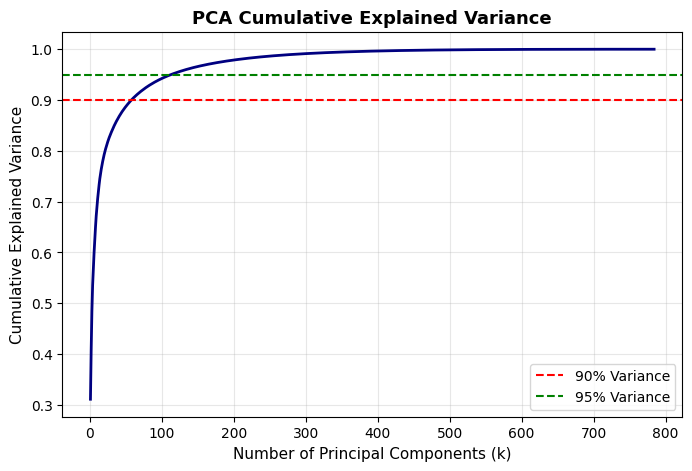

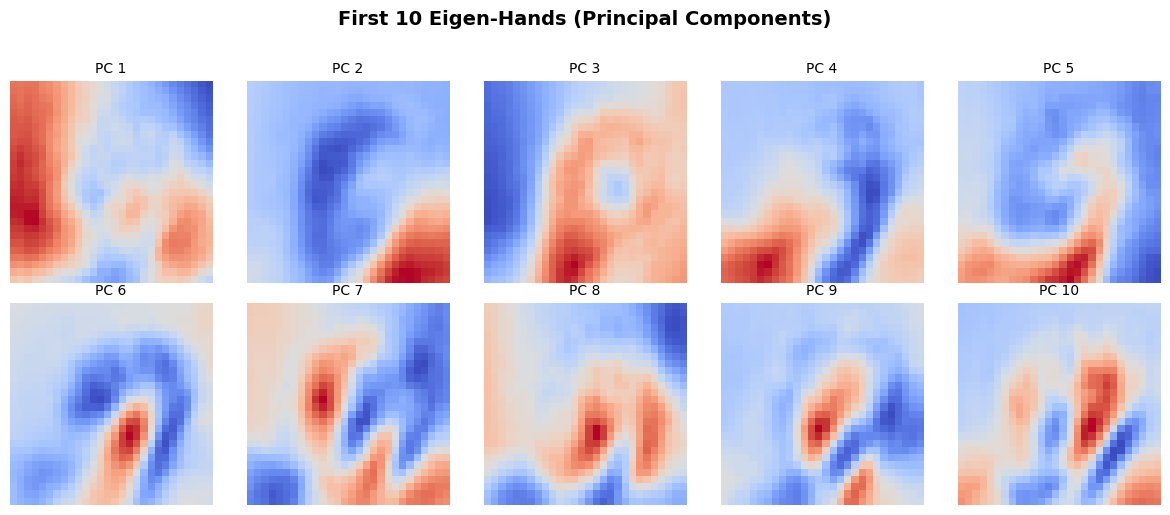

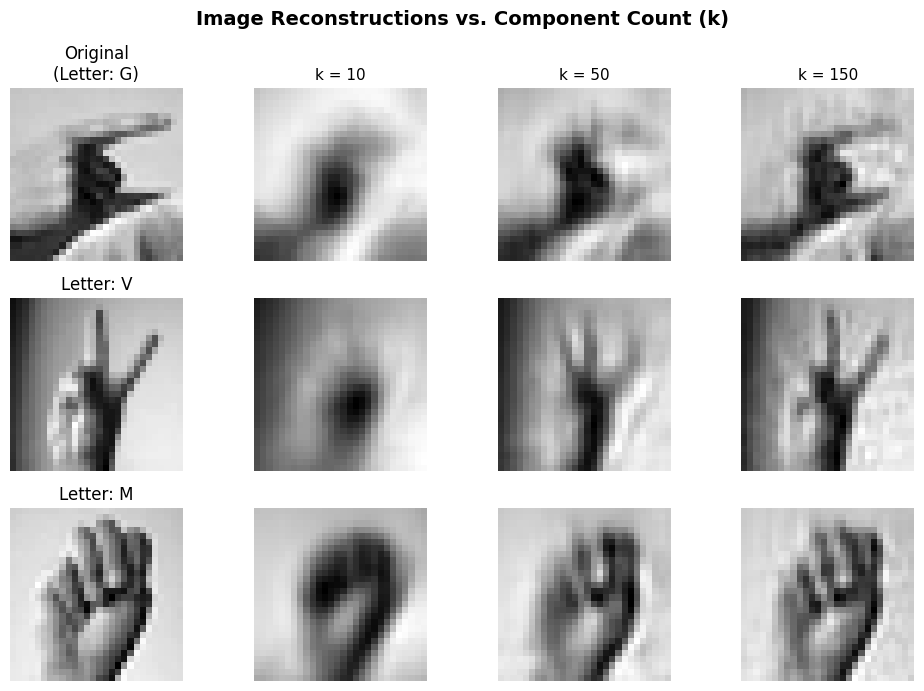

In [10]:
# 1. Fit PCA on training set only with max components (784)
pca_full = PCA(n_components=784, random_state=SEED)
pca_full.fit(X_train)

cum_explained_variance = np.cumsum(pca_full.explained_variance_ratio_)

# Plot Cumulative Explained Variance
plt.figure(figsize=(8, 5))
plt.plot(range(1, 785), cum_explained_variance, color='navy', linewidth=2)
plt.axhline(y=0.90, color='r', linestyle='--', label='90% Variance')
plt.axhline(y=0.95, color='g', linestyle='--', label='95% Variance')
plt.xlabel("Number of Principal Components (k)", fontsize=11)
plt.ylabel("Cumulative Explained Variance", fontsize=11)
plt.title("PCA Cumulative Explained Variance", fontsize=13, fontweight='bold')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# 2. Display the First 10 Eigen-hands (Principal Components as 28x28 images)
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for i, ax in enumerate(axes.flat):
    eigen_hand = pca_full.components_[i].reshape(28, 28)
    ax.imshow(eigen_hand, cmap='coolwarm')
    ax.set_title(f"PC {i+1}", fontsize=10)
    ax.axis('off')
plt.suptitle("First 10 Eigen-Hands (Principal Components)", fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

# 3. Reconstruct Sample Images from 10, 50, and 150 Components
sample_indices = [0, 5, 13] # Grab a few test images
k_values = [10, 50, 150]

fig, axes = plt.subplots(len(sample_indices), len(k_values) + 1, figsize=(10, 7))

for row_idx, img_idx in enumerate(sample_indices):
    orig_img = X_test[img_idx]
    true_label = y_test[img_idx]
    true_letter = get_letter(true_label)

    # Original
    axes[row_idx, 0].imshow(orig_img.reshape(28, 28), cmap='gray')
    axes[row_idx, 0].set_title(f"Original\n(Letter: {true_letter})" if row_idx == 0 else f"Letter: {true_letter}")
    axes[row_idx, 0].axis('off')
    # Reconstructions for each k
    for col_idx, k in enumerate(k_values):
        pca_k = PCA(n_components=k, random_state=SEED).fit(X_train)
        img_transformed = pca_k.transform(orig_img.reshape(1, -1))
        img_reconstructed = pca_k.inverse_transform(img_transformed).reshape(28, 28)

        axes[row_idx, col_idx + 1].imshow(img_reconstructed, cmap='gray')
        if row_idx == 0:
            axes[row_idx, col_idx + 1].set_title(f"k = {k}", fontsize=11)
        axes[row_idx, col_idx + 1].axis('off')

plt.suptitle("Image Reconstructions vs. Component Count (k)", fontsize=14, fontweight='bold', y=0.98)
plt.tight_layout()
plt.show()